### Modelado y Definición de la Señal de Referencia
Establecemos un escenario de referencia ideal empleando una función matemática armónica pura (sinusoidal). Para ello, realizamos un muestreo uniforme sobre el dominio continuo $x ∈ [0, 1]$ utilizando $N = 100$ puntos discretos:

$$y(x) = 	ext{sen}(2\pi \cdot x)$$

Esta función representará el comportamiento teórico y limpio de nuestro sistema físico antes de introducir cualquier tipo de perturbación externa.

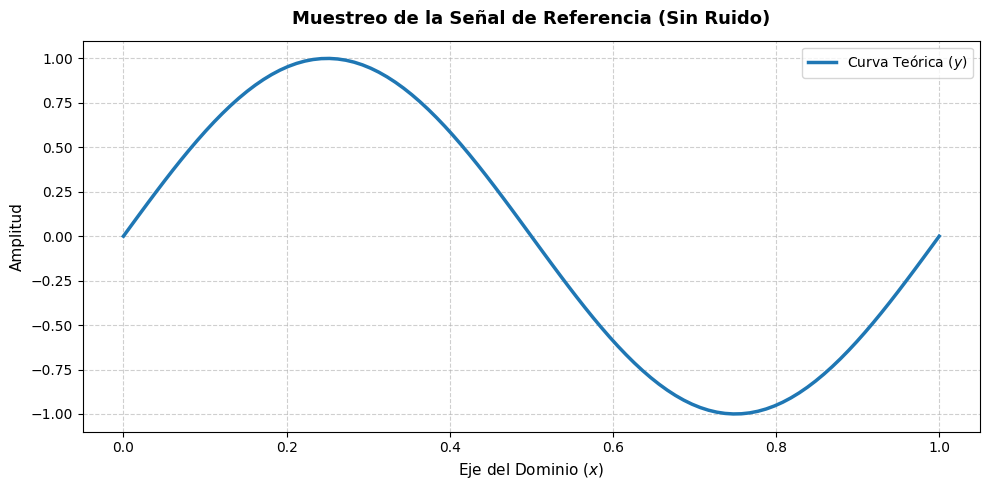

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de parámetros del dominio y muestreo
total_puntos = 100
eje_x = np.linspace(0, 1, total_puntos)[:, np.newaxis]

# 2. Generación de la señal senoidal libre de ruido
frecuencia_angular = 2 * np.pi
senial_teorica = np.sin(frecuencia_angular * eje_x)

# 3. Configuración y visualización del gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# Trazado de la curva con nuevo estilo y color (Azul Real / Royal Blue)
ax.plot(
    eje_x,
    senial_teorica,
    label="Curva Teórica ($y$)",
    color="#1f77b4",
    linewidth=2.5
)

# Personalización de títulos y etiquetas de los ejes
ax.set_title("Muestreo de la Señal de Referencia (Sin Ruido)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Eje del Dominio ($x$)", fontsize=11)
ax.set_ylabel("Amplitud", fontsize=11)

# Rejilla, leyenda y ajustes finales
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(fontsize=10, loc="upper right")

plt.tight_layout()
plt.show()

### Simulación de Ruido y Perturbaciones Gaussianas
Para modelar un entorno experimental más realista, contaminamos la señal pura mediante Ruido Blanco Gaussiano Aditivo (AWGN), definido como $n \sim \mathcal{N}(0, \sigma^2)$. El nivel de ruido se ajusta en función de la Relación Señal-Ruido deseada ($SNR_{dB}$):

1. **Cálculo de la Energía de la Señal ($P_s$):** $P_s = \frac{1}{N} \sum y_i^2$
2. **Varianza Teórica del Ruido ($P_n$):** $P_n = \frac{P_s}{10^{SNR_{dB}/10}}$
3. **Construcción de la Señal Observada ($t$):** $t = y + n$

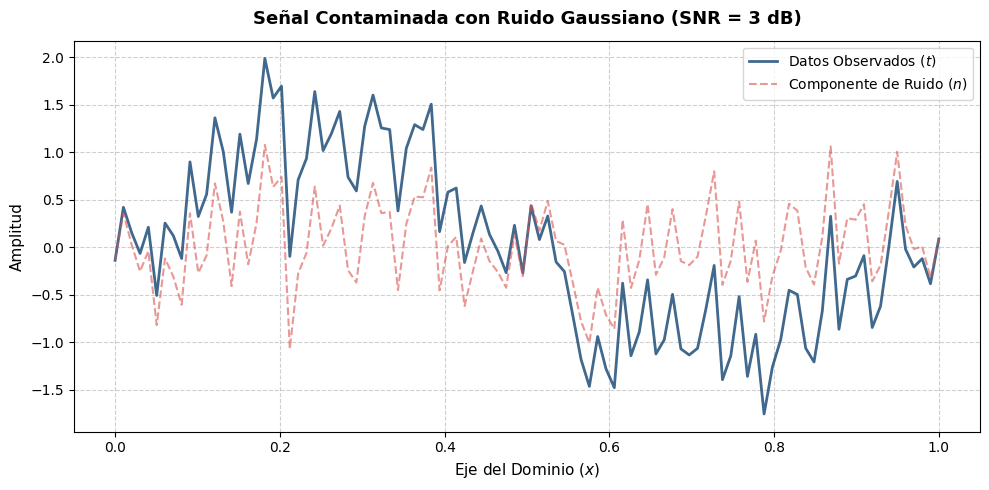

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def agregar_ruido_awgn(senal_entrada, snr_db):
    """
    Añade Ruido Blanco Gaussiano Aditivo (AWGN) a una señal según el nivel SNR (dB) indicado.
    """
    # Cálculo de la potencia de la señal y varianza requerida del ruido
    potencia_signal = np.mean(senal_entrada ** 2)
    var_ruido = potencia_signal / (10 ** (snr_db / 10.0))
    sigma_ruido = np.sqrt(var_ruido)

    # Generación de la muestra aleatoria de ruido con distribución normal
    ruido = np.random.normal(0, sigma_ruido, size=senal_entrada.shape)
    senal_contaminada = senal_entrada + ruido

    return senal_contaminada, ruido, var_ruido

# 1. Aplicación de ruido con un SNR de 3 dB
snr_objetivo = 3
senal_ruidosa, muestra_ruido, potencia_r = agregar_ruido_awgn(senial_teorica, snr_objetivo)

# 2. Configuración del gráfico orientado a objetos
fig, ax = plt.subplots(figsize=(10, 5))

# Trazado de la señal contaminada y el componente de ruido con nuevo estilo de color
ax.plot(
    eje_x,
    senal_ruidosa,
    label="Datos Observados ($t$)",
    color="#1f4e79",
    alpha=0.85,
    linewidth=2
)
ax.plot(
    eje_x,
    muestra_ruido,
    label="Componente de Ruido ($n$)",
    color="#d9534f",
    alpha=0.6,
    linestyle="--",
    linewidth=1.5
)

# Personalización de títulos, etiquetas y cuadrícula
ax.set_title(f"Señal Contaminada con Ruido Gaussiano (SNR = {snr_objetivo} dB)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Eje del Dominio ($x$)", fontsize=11)
ax.set_ylabel("Amplitud", fontsize=11)

ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(fontsize=10, loc="upper right")

plt.tight_layout()
plt.show()

### Formulación del Espacio Polinomial y Estimación Ridge
1. **Construcción de la Matriz de Diseño ($\Phi$):** Mapeamos los datos unidimensionales $x$ a un espacio de características polinomial de grado $Q$:
   $$\Phi(x) = [1, x, x^2, \dots, x^{Q-1}]$$

2. **Ajuste Regularizado mediante Regresión Ridge ($L_2$):** Resolvemos el vector de parámetros analíticamente aplicando la penalización correspondiente sobre las ecuaciones normales:
   $$w = (\Phi^T \Phi + \lambda I)^{-1} \Phi^T y$$
   Aquí, el parámetro de penalización $\lambda$ controla directamente el nivel de suavizado del modelo.

In [ ]:
import numpy as np

def construir_matriz_diseno(valores_entrada, grado_polinomio):
    """
    Crea una matriz de diseño de Vandermonde para una expansión polinomial.
    Incluye potencias desde 0 hasta grado_polinomio (inclusive).
    """
    vector_col = np.asarray(valores_entrada).reshape(-1, 1)
    # Se añade +1 para incluir el término del grado completo (x^0, x^1, ..., x^grado)
    return np.column_stack([vector_col**potencia for potencia in range(grado_polinomio + 1)])

# Inicialización de la matriz de características con polinomio de grado 10
# (Usando eje_x definido en los bloques anteriores)
matriz_diseno = construir_matriz_diseno(eje_x, 10)


def ajustar_modelo_lineal(matriz_phi, vector_salida, coeficiente_regularizacion):
    """
    Resuelve el sistema lineal empleando la pseudoinversa con regularización Ridge (L2).
    """
    dimension_regularizador = matriz_phi.shape[1]
    matriz_regularizadora = coeficiente_regularizacion * np.eye(dimension_regularizador)

    # Ecuación normal regularizada: w = (Phi^T * Phi + lambda * I)^(-1) * Phi^T * y
    inversa_solucion = np.linalg.pinv(matriz_phi.T @ matriz_phi + matriz_regularizadora)
    proyeccion_salida = matriz_phi.T @ vector_salida

    return inversa_solucion @ proyeccion_salida

### Diagnóstico Inicial: Ajuste mediante Mínimos Cuadrados Ordinarios (OLS)
Para establecer un punto de comparación sin regularización, calculamos los pesos fijando el hiperparámetro de penalización $\lambda = 0$. Esto equivale a resolver el problema clásico de mínimos cuadrados ordinarios.

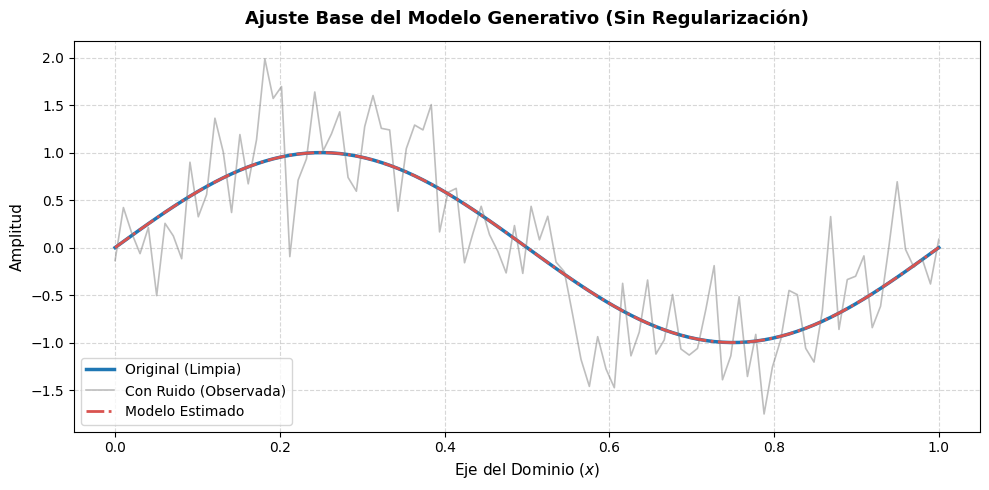

In [ ]:
# Ajuste inicial sobre la señal limpia para evaluar la capacidad de representación de la base
# Nota: Se debe pasar 'senial_teorica' en lugar de 'eje_x' como variable objetivo (y)
pesos_limpios = ajustar_modelo_lineal(matriz_diseno, senial_teorica, 0)
prediccion_modelo = matriz_diseno @ pesos_limpios

# Configuración del gráfico con el estilo actualizado (fig, ax)
fig, ax = plt.subplots(figsize=(10, 5))

# Trazado de las curvas con la paleta de colores renovada
ax.plot(
    eje_x,
    senial_teorica,
    label="Original (Limpia)",
    color="#1f77b4",
    linewidth=2.5
)
ax.plot(
    eje_x,
    senal_ruidosa,
    label="Con Ruido (Observada)",
    color="#7f7f7f",
    alpha=0.5,
    linewidth=1.2
)
ax.plot(
    eje_x,
    prediccion_modelo,
    label="Modelo Estimado",
    color="#d9534f",
    linestyle="-.",
    linewidth=2
)

# Títulos, etiquetas y formato
ax.set_title("Ajuste Base del Modelo Generativo (Sin Regularización)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Eje del Dominio ($x$)", fontsize=11)
ax.set_ylabel("Amplitud", fontsize=11)

ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=10, loc="lower left")

plt.tight_layout()
plt.show()

### Comparación Analítica de Paradigmas de Estimación
Estudiaremos el rendimiento de cuatro formulaciones algorítmicas distintas al tratar de recuperar la señal a partir de los datos ruidosos $t$:

1. **Mínimos Cuadrados (OLS) / Máxima Verosimilitud (ML):** Suponen ruido blanco y buscan minimizar directamente la desviación cuadrática empírica. No incorporan priors sobre el tamaño de los pesos ($\lambda = 0$):
   $$w_{ML} = (\Phi^T \Phi)^{-1} \Phi^T t$$

2. **Mínimos Cuadrados Regularizados (Ridge) / Máximo Posteriori (MAP):** Estabilizan la inversión matricial al introducir una densidad de probabilidad a priori de tipo Gaussiana sobre los parámetros de peso $w \sim \mathcal{N}(0, \alpha^{-1} I)$. La equivalencia matemática se formaliza con:
   $$\lambda = \frac{\sigma^2}{\sigma_w^2}$$
   $$w_{MAP} = (\Phi^T \Phi + \lambda I)^{-1} \Phi^T t$$

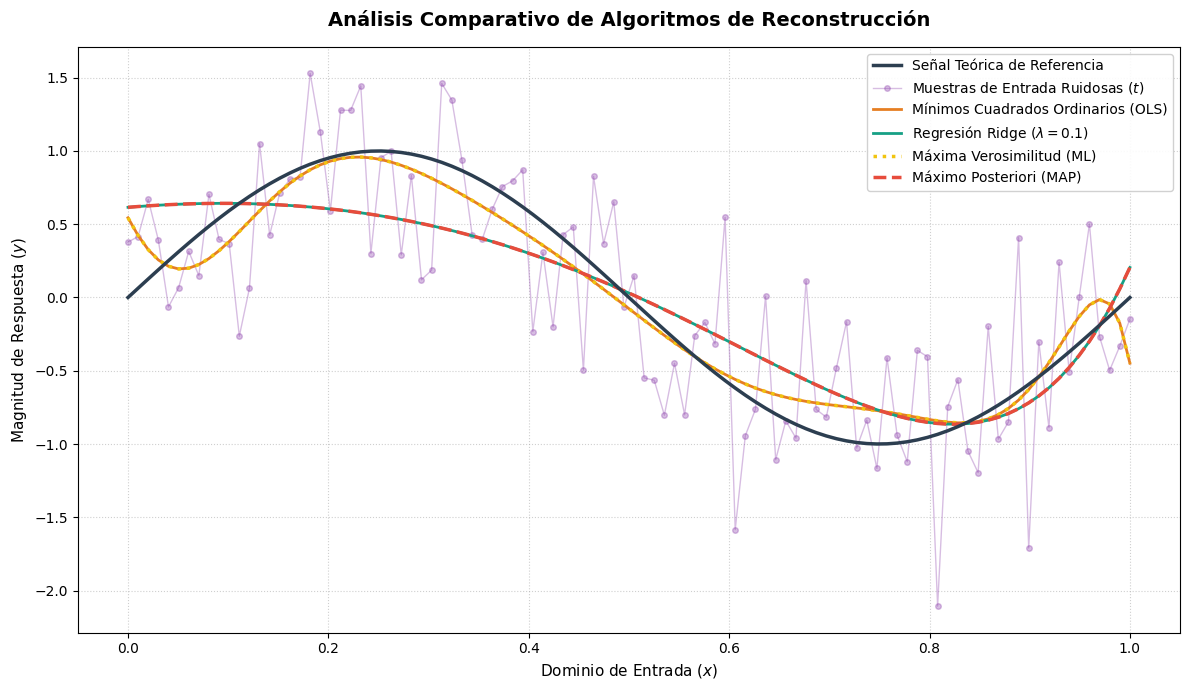

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generación de una nueva muestra con ruido para el análisis comparativo
senal_ruidosa, vector_ruido, potencia_ruido = agregar_ruido_awgn(senial_teorica, 3)

# 1. Enfoque de Mínimos Cuadrados Ordinarios (OLS)
pesos_ols = ajustar_modelo_lineal(matriz_diseno, senal_ruidosa, coeficiente_regularizacion=0)
prediccion_ols = matriz_diseno @ pesos_ols

# 2. Enfoque Regularizado Tikhonov / Ridge Regression
penalizacion_alpha = 0.1
pesos_ridge = ajustar_modelo_lineal(matriz_diseno, senal_ruidosa, coeficiente_regularizacion=penalizacion_alpha)
prediccion_ridge = matriz_diseno @ pesos_ridge

# 3. Solución por Máxima Verosimilitud (ML) -> Idéntica a OLS
pesos_ml = pesos_ols
prediccion_ml = prediccion_ols

# 4. Solución por Máximo Posteriori (MAP) -> Idéntica a Ridge
pesos_map = pesos_ridge
prediccion_map = prediccion_ridge

# Visualización profesional del desempeño de los diferentes reconstrucores
fig, ax = plt.subplots(figsize=(12, 7))

# Trazado de señales de referencia y muestras ruidosas
ax.plot(
    eje_x,
    senial_teorica,
    color="#2c3e50",
    linestyle="-",
    label="Señal Teórica de Referencia",
    linewidth=2.5,
    zorder=5
)
ax.plot(
    eje_x,
    senal_ruidosa,
    color="#8e44ad",
    alpha=0.35,
    marker="o",
    markersize=4,
    label="Muestras de Entrada Ruidosas ($t$)",
    linewidth=1
)

# Trazado de las estimaciones del modelo
ax.plot(
    eje_x,
    prediccion_ols,
    color="#e67e22",
    linestyle="-",
    label="Mínimos Cuadrados Ordinarios (OLS)",
    linewidth=2
)
ax.plot(
    eje_x,
    prediccion_ridge,
    color="#16a085",
    linestyle="-",
    label=r"Regresión Ridge ($\lambda=0.1$)",
    linewidth=2
)
ax.plot(
    eje_x,
    prediccion_ml,
    color="#f1c40f",
    linestyle=":",
    label="Máxima Verosimilitud (ML)",
    linewidth=2.5
)
ax.plot(
    eje_x,
    prediccion_map,
    color="#e74c3c",
    linestyle="--",
    label="Máximo Posteriori (MAP)",
    linewidth=2.5
)

# Detalles del gráfico
ax.set_title("Análisis Comparativo de Algoritmos de Reconstrucción", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Dominio de Entrada ($x$)", fontsize=11)
ax.set_ylabel("Magnitud de Respuesta ($y$)", fontsize=11)

ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.show()

### Conclusiones y Análisis de los Estimadores

Al examinar los gráficos de reconstrucción de la señal ruidosa, se destacan las siguientes observaciones:

1. **Inestabilidad de OLS / ML (Sobreajuste):**
   La estimación por **Mínimos Cuadrados Ordinarios (OLS)** y **Máxima Verosimilitud (ML)** carece de restricciones. Al utilizar un polinomio de grado elevado, el modelo intenta ajustarse de forma estricta a las fluctuaciones del ruido en lugar de la tendencia armónica real. Esto causa valores extremos en los pesos y oscilaciones severas en los extremos del dominio.

2. **Efecto de la Regularización en Ridge / MAP:**
   La penalización cuadrática en la regresión **Ridge** (equivalente al enfoque bayesiano **MAP** con prior Gaussiano) limita el valor de los coeficientes. Esto evita cambios drásticos y produce curvas notablemente más suaves y estables que ignoran las fluctuaciones de alta frecuencia del ruido.

3. **Equivalencia de los Enfoques:**
   * Se valida de forma práctica que **OLS** es numéricamente idéntico a **ML** bajo hipótesis de ruido gaussiano.
   * Del mismo modo, se confirma la equivalencia exacta entre la solución regularizada de **Ridge** y el estimador bayesiano **MAP** con un prior gaussiano de media cero.